# GeoAI-Based Detection of Urban Growth Hotspots in Kaduna Metropolis, Nigeria

This Google Colab notebook implements a complete workflow for detecting urban growth hotspots in Kaduna Metropolis using Google Earth Engine, Landsat imagery, Random Forest classification, built-up extraction, change detection, land conversion analysis, and grid-based hotspot mapping.

**Main outputs**
- Multi-year land-use/land-cover maps
- Built-up area statistics
- Urban expansion trend chart
- New built-up growth map
- Urban growth hotspot grid
- Land conversion statistics
- Exported maps and tables to Google Drive

**Note:** This first version uses ESA WorldCover 2020 as a training reference. For publishable results, improve it with manually digitized training samples from high-resolution imagery.

## 1. Install and import required libraries

In [15]:
!pip install geemap -q

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt

## 2. Authenticate and initialize Google Earth Engine

In [16]:
import ee

ee.Authenticate()

PROJECT_ID = "geoai-502123"

ee.Initialize(project=PROJECT_ID)

print("Google Earth Engine initialized successfully.")

Google Earth Engine initialized successfully.


## 3. Define Kaduna Metropolis study area

In [17]:
# Load GAUL Level 2 administrative boundaries
gaul_l2 = ee.FeatureCollection("FAO/GAUL/2015/level2")

# Select Kaduna Metropolitan LGAs
kaduna_metro = gaul_l2.filter(
    ee.Filter.And(
        ee.Filter.eq("ADM0_NAME", "Nigeria"),
        ee.Filter.eq("ADM1_NAME", "Kaduna"),
        ee.Filter.inList("ADM2_NAME", [
            "Kaduna North",
            "Kaduna South",
            "Chikun",
            "Igabi"
        ])
    )
)

# Dissolve selected LGAs into one geometry
aoi = kaduna_metro.geometry()

print("Number of selected LGA features:", kaduna_metro.size().getInfo())

# Display AOI
Map = geemap.Map(center=[10.52, 7.44], zoom=10)
Map.addLayer(kaduna_metro, {}, "Kaduna Metropolitan Area")
Map

Number of selected LGA features: 4


Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## Optional: Inspect Kaduna LGA names

In [18]:
kaduna_lgas = gaul_l2.filter(
    ee.Filter.And(
        ee.Filter.eq("ADM0_NAME", "Nigeria"),
        ee.Filter.eq("ADM1_NAME", "Kaduna")
    )
)

print(kaduna_lgas.aggregate_array("ADM2_NAME").getInfo())

['Ikara', 'Makarfi', 'Kudan', 'Kubau', 'Chikun', 'Kajuru', 'Kachia', "Jema'a", 'Sanga', 'Kagarko', 'Giwa', 'Birnin Gwari', 'Sabon Gari', 'Soba', 'Zaria', 'Igabi', 'Kauru', 'Lere', 'Kaduna North', 'Kaduna South', 'Zangon Kataf', 'Kaura', 'Jaba']


## 4. Landsat preprocessing functions

In [19]:
def mask_landsat_sr(image):
    """Masks cloud and cloud shadow from Landsat Collection 2 Level 2 imagery."""
    qa = image.select("QA_PIXEL")
    cloud = qa.bitwiseAnd(1 << 3).neq(0)
    shadow = qa.bitwiseAnd(1 << 4).neq(0)
    mask = cloud.Or(shadow).Not()
    return image.updateMask(mask)


def scale_landsat_sr(image):
    """Applies scale factor to Landsat surface reflectance bands."""
    optical = image.select("SR_B.*").multiply(0.0000275).add(-0.2)
    return image.addBands(optical, None, True)


def rename_landsat_57(image):
    """Rename Landsat 5/7 bands into common names."""
    return image.select(
        ["SR_B1", "SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B7"],
        ["blue", "green", "red", "nir", "swir1", "swir2"]
    )


def rename_landsat_89(image):
    """Rename Landsat 8/9 bands into common names."""
    return image.select(
        ["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"],
        ["blue", "green", "red", "nir", "swir1", "swir2"]
    )

## 5. Create annual Landsat dry-season composite

In [29]:
def get_landsat_collection(year, aoi, start_month=1, end_month=12):
    """
    Returns Landsat image collection for a year and month range.
    Uses all available Landsat sensors for better coverage.
    """

    start = ee.Date.fromYMD(year, start_month, 1)
    end = ee.Date.fromYMD(year, end_month, 28).advance(1, "month")

    # Landsat 5
    landsat5 = (
        ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
        .filterBounds(aoi)
        .filterDate(start, end)
        .map(mask_landsat_sr)
        .map(scale_landsat_sr)
        .map(rename_landsat_57)
    )

    # Landsat 7
    landsat7 = (
        ee.ImageCollection("LANDSAT/LE07/C02/T1_L2")
        .filterBounds(aoi)
        .filterDate(start, end)
        .map(mask_landsat_sr)
        .map(scale_landsat_sr)
        .map(rename_landsat_57)
    )

    # Landsat 8
    landsat8 = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(aoi)
        .filterDate(start, end)
        .map(mask_landsat_sr)
        .map(scale_landsat_sr)
        .map(rename_landsat_89)
    )

    # Landsat 9
    landsat9 = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(aoi)
        .filterDate(start, end)
        .map(mask_landsat_sr)
        .map(scale_landsat_sr)
        .map(rename_landsat_89)
    )

    if year < 2013:
        collection = landsat5.merge(landsat7)

    elif year < 2022:
        collection = landsat8

    else:
        collection = landsat8.merge(landsat9)

    return collection


def get_landsat_composite(year, aoi):
    """
    Creates a Landsat composite.
    First tries dry season. If empty, falls back to full year.
    """

    dry_early = get_landsat_collection(year, aoi, 1, 3)
    dry_late = get_landsat_collection(year, aoi, 11, 12)
    dry_collection = dry_early.merge(dry_late)

    dry_count = dry_collection.size().getInfo()

    if dry_count > 0:
        print(f"{year}: using dry-season collection with {dry_count} images")
        composite = dry_collection.median().clip(aoi)
        return composite.set("year", year).set("image_count", dry_count)

    full_collection = get_landsat_collection(year, aoi, 1, 12)
    full_count = full_collection.size().getInfo()

    if full_count > 0:
        print(f"{year}: dry season empty, using full-year collection with {full_count} images")
        composite = full_collection.median().clip(aoi)
        return composite.set("year", year).set("image_count", full_count)

    raise ValueError(f"No Landsat images found for {year}. Check AOI or date range.")

## 6. Add spectral indices

In [30]:
def add_indices(image):
    """Adds spectral indices useful for urban growth detection."""
    ndvi = image.normalizedDifference(["nir", "red"]).rename("NDVI")
    ndbi = image.normalizedDifference(["swir1", "nir"]).rename("NDBI")
    mndwi = image.normalizedDifference(["green", "swir1"]).rename("MNDWI")

    bsi = image.expression(
        "((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue))",
        {
            "swir1": image.select("swir1"),
            "red": image.select("red"),
            "nir": image.select("nir"),
            "blue": image.select("blue")
        }
    ).rename("BSI")

    return image.addBands([ndvi, ndbi, mndwi, bsi])

In [31]:
print("Selected Kaduna Metro features:", kaduna_metro.size().getInfo())
print("Selected LGA names:", kaduna_metro.aggregate_array("ADM2_NAME").getInfo())

Selected Kaduna Metro features: 4
Selected LGA names: ['Chikun', 'Igabi', 'Kaduna North', 'Kaduna South']


## 7. Generate annual composites

In [32]:
years = [2000, 2005, 2010, 2015, 2020, 2025]
composites = {}

for year in years:
    img = get_landsat_composite(year, aoi)
    img = add_indices(img)
    composites[year] = img
    print(f"Composite prepared for {year}; image count:", img.get("image_count").getInfo())

2000: using dry-season collection with 8 images
Composite prepared for 2000; image count: 8
2005: using dry-season collection with 30 images
Composite prepared for 2005; image count: 30
2010: using dry-season collection with 25 images
Composite prepared for 2010; image count: 25
2015: using dry-season collection with 39 images
Composite prepared for 2015; image count: 39
2020: using dry-season collection with 38 images
Composite prepared for 2020; image count: 38
2025: using dry-season collection with 78 images
Composite prepared for 2025; image count: 78


## 8. Visualize Landsat RGB composites

In [33]:
Map = geemap.Map(center=[10.52, 7.44], zoom=10)
vis_rgb = {"bands": ["red", "green", "blue"], "min": 0.02, "max": 0.3}

for year in years:
    Map.addLayer(composites[year], vis_rgb, f"Landsat RGB {year}")

Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 9. Prepare training labels using ESA WorldCover 2020

In [34]:
# Load ESA WorldCover 2020
worldcover = ee.Image("ESA/WorldCover/v100/2020").select("Map").clip(aoi)

# ESA classes: 10 Trees, 20 Shrubland, 30 Grassland, 40 Cropland, 50 Built-up, 60 Bare/Sparse, 80 Water
class_image = (
    worldcover
    .remap([50, 10, 20, 30, 40, 60, 80], [1, 2, 2, 2, 3, 4, 5])
    .rename("class")
)

class_vis = {"min": 1, "max": 5, "palette": ["red", "green", "yellow", "brown", "blue"]}

Map = geemap.Map(center=[10.52, 7.44], zoom=10)
Map.addLayer(class_image, class_vis, "Simplified WorldCover Training Labels")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 10. Create training samples

In [35]:
feature_bands = ["blue", "green", "red", "nir", "swir1", "swir2", "NDVI", "NDBI", "MNDWI", "BSI"]

training_image = composites[2020].select(feature_bands).addBands(class_image)

samples = training_image.stratifiedSample(
    numPoints=800,
    classBand="class",
    region=aoi,
    scale=30,
    classValues=[1, 2, 3, 4, 5],
    classPoints=[800, 800, 800, 600, 300],
    seed=42,
    geometries=True
)

print("Number of samples:", samples.size().getInfo())

Number of samples: 3300


## 11. Split samples into training and validation sets

In [36]:
samples = samples.randomColumn("random", seed=42)
training_samples = samples.filter(ee.Filter.lt("random", 0.7))
validation_samples = samples.filter(ee.Filter.gte("random", 0.7))

print("Training samples:", training_samples.size().getInfo())
print("Validation samples:", validation_samples.size().getInfo())

Training samples: 2311
Validation samples: 989


## 12. Train Random Forest classifier

In [37]:
rf_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=200,
    variablesPerSplit=None,
    minLeafPopulation=1,
    bagFraction=0.7,
    seed=42
).train(
    features=training_samples,
    classProperty="class",
    inputProperties=feature_bands
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 13. Validate the classifier

In [38]:
validated = validation_samples.classify(rf_classifier)
confusion_matrix = validated.errorMatrix("class", "classification")

print("Confusion Matrix:")
print(confusion_matrix.getInfo())
print("Overall Accuracy:", confusion_matrix.accuracy().getInfo())
print("Kappa:", confusion_matrix.kappa().getInfo())

Confusion Matrix:
[[0, 0, 0, 0, 0, 0], [0, 202, 10, 11, 24, 3], [0, 2, 183, 31, 16, 0], [0, 6, 34, 178, 24, 0], [0, 40, 21, 38, 68, 12], [0, 11, 0, 1, 4, 70]]
Overall Accuracy: 0.7087967644084934
Kappa: 0.625715010321904


## 14. Classify land use/land cover for all selected years

In [39]:
classified_images = {}

for year in years:
    classified = composites[year].select(feature_bands).classify(rf_classifier).clip(aoi)
    classified_images[year] = classified
    print(f"Classified image generated for {year}")

Classified image generated for 2000
Classified image generated for 2005
Classified image generated for 2010
Classified image generated for 2015
Classified image generated for 2020
Classified image generated for 2025


## 15. Visualize classified land-cover maps

In [40]:
lulc_vis = {"min": 1, "max": 5, "palette": ["red", "green", "yellow", "brown", "blue"]}

Map = geemap.Map(center=[10.52, 7.44], zoom=10)
for year in years:
    Map.addLayer(classified_images[year], lulc_vis, f"LULC {year}")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 16. Extract built-up area for each year

In [41]:
builtup_images = {}
for year in years:
    builtup = classified_images[year].eq(1).rename("builtup").clip(aoi)
    builtup_images[year] = builtup
print("Built-up masks created for all years.")

Built-up masks created for all years.


## 17. Calculate built-up area statistics

In [ ]:
def calculate_builtup_area(image, year, aoi):
    """Calculates built-up area in square kilometers."""
    area_image = image.multiply(ee.Image.pixelArea()).divide(1e6)
    area = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=30,
        maxPixels=1e13
    ).get("builtup")
    return {"year": year, "builtup_area_sqkm": area}

area_results = []
for year in years:
    area_results.append(calculate_builtup_area(builtup_images[year], year, aoi))

area_data = []
for item in area_results:
    area_data.append({"year": item["year"], "builtup_area_sqkm": item["builtup_area_sqkm"].getInfo()})

area_df = pd.DataFrame(area_data)
area_df

## 18. Plot urban built-up growth trend

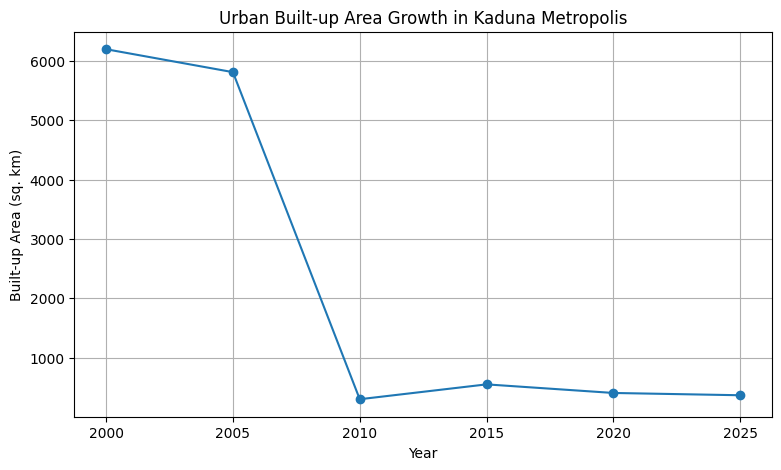

In [43]:
plt.figure(figsize=(9, 5))
plt.plot(area_df["year"], area_df["builtup_area_sqkm"], marker="o")
plt.xlabel("Year")
plt.ylabel("Built-up Area (sq. km)")
plt.title("Urban Built-up Area Growth in Kaduna Metropolis")
plt.grid(True)
plt.show()

## 19. Calculate urban expansion between selected years

In [44]:
area_df["change_sqkm"] = area_df["builtup_area_sqkm"].diff()
area_df["percentage_change"] = area_df["builtup_area_sqkm"].pct_change() * 100
area_df

,year,builtup_area_sqkm,change_sqkm,percentage_change
0,2000,6195.282640,NaN,NaN
1,2005,5809.012712,-386.269927,-6.234904
2,2010,299.566613,-5509.446099,-94.843072
3,2015,549.617353,250.050740,83.470830
4,2020,404.982030,-144.635323,-26.315640
5,2025,366.415462,-38.566568,-9.523032


## 20. Detect new built-up growth from 2000 to 2025

In [45]:
builtup_2000 = builtup_images[2000]
builtup_2025 = builtup_images[2025]

new_growth_2000_2025 = builtup_2025.And(builtup_2000.Not()).rename("new_growth")
growth_vis = {"min": 0, "max": 1, "palette": ["white", "red"]}

Map = geemap.Map(center=[10.52, 7.44], zoom=10)
Map.addLayer(new_growth_2000_2025, growth_vis, "New Built-up Growth 2000-2025")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 21. Detect built-up growth for each interval

In [46]:
growth_intervals = {}
for i in range(len(years) - 1):
    y1 = years[i]
    y2 = years[i + 1]
    growth = builtup_images[y2].And(builtup_images[y1].Not()).rename("growth")
    growth_intervals[f"{y1}_{y2}"] = growth
    print(f"Growth map created for {y1} to {y2}")

Growth map created for 2000 to 2005
Growth map created for 2005 to 2010
Growth map created for 2010 to 2015
Growth map created for 2015 to 2020
Growth map created for 2020 to 2025


## 22. Visualize interval growth maps

In [47]:
Map = geemap.Map(center=[10.52, 7.44], zoom=10)
for interval, image in growth_intervals.items():
    Map.addLayer(image, growth_vis, f"Growth {interval}")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 23. Create grid for hotspot analysis

In [48]:
grid = geemap.fishnet(aoi, rows=40, cols=40)

Map = geemap.Map(center=[10.52, 7.44], zoom=10)
Map.addLayer(grid, {}, "Hotspot Analysis Grid")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 24. Calculate new-growth area per grid cell

In [49]:
def add_growth_area(feature):
    """Calculates new built-up growth area inside each grid cell."""
    growth_area = new_growth_2000_2025.multiply(ee.Image.pixelArea()).divide(1e6)
    area = growth_area.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=feature.geometry(),
        scale=30,
        maxPixels=1e13
    ).get("new_growth")
    return feature.set("growth_sqkm", area)

growth_grid = grid.map(add_growth_area)
print("Growth grid prepared:", growth_grid.size().getInfo())

Growth grid prepared: 966


## 25. Classify hotspot intensity

In [50]:
def classify_hotspot(feature):
    growth = ee.Number(feature.get("growth_sqkm"))
    hotspot_class = ee.Algorithms.If(
        growth.gte(1.0), 5,
        ee.Algorithms.If(
            growth.gte(0.5), 4,
            ee.Algorithms.If(
                growth.gte(0.2), 3,
                ee.Algorithms.If(growth.gt(0), 2, 1)
            )
        )
    )
    return feature.set("hotspot_class", hotspot_class)

hotspot_grid = growth_grid.map(classify_hotspot)
print("Hotspot grid classified.")

Hotspot grid classified.


## 26. Visualize urban growth hotspot grid

In [51]:
hotspot_vis = {"min": 1, "max": 5, "palette": ["f7f7f7", "fee5d9", "fcae91", "fb6a4a", "cb181d"]}

hotspot_image = hotspot_grid.reduceToImage(
    properties=["hotspot_class"],
    reducer=ee.Reducer.first()
)

Map = geemap.Map(center=[10.52, 7.44], zoom=10)
Map.addLayer(hotspot_image, hotspot_vis, "Urban Growth Hotspots")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 27. Land conversion analysis

In [52]:
lulc_2000 = classified_images[2000]
lulc_2025 = classified_images[2025]

new_builtup_mask = lulc_2025.eq(1).And(lulc_2000.neq(1))
converted_from = lulc_2000.updateMask(new_builtup_mask).rename("converted_from")

conversion_vis = {"min": 1, "max": 5, "palette": ["red", "green", "yellow", "brown", "blue"]}

Map = geemap.Map(center=[10.52, 7.44], zoom=10)
Map.addLayer(converted_from, conversion_vis, "Land Converted to Built-up by 2025")
Map.addLayer(kaduna_metro, {}, "Kaduna Metro Boundary")
Map

Map(center=[10.52, 7.44], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## 28. Calculate land conversion statistics

In [53]:
class_names = {1: "Built-up", 2: "Vegetation", 3: "Cropland", 4: "Bare land", 5: "Water"}
conversion_stats = []

for class_id, class_name in class_names.items():
    class_area = converted_from.eq(class_id).multiply(ee.Image.pixelArea()).divide(1e6)
    area = class_area.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=30,
        maxPixels=1e13
    ).get("converted_from")
    conversion_stats.append({
        "original_class_id": class_id,
        "original_class_name": class_name,
        "converted_to_builtup_sqkm": area.getInfo()
    })

conversion_df = pd.DataFrame(conversion_stats)
conversion_df

,original_class_id,original_class_name,converted_to_builtup_sqkm
0,1,Built-up,0.000000
1,2,Vegetation,0.035712
2,3,Cropland,0.087909
3,4,Bare land,22.654891
4,5,Water,33.031274


## 29. Plot land conversion chart

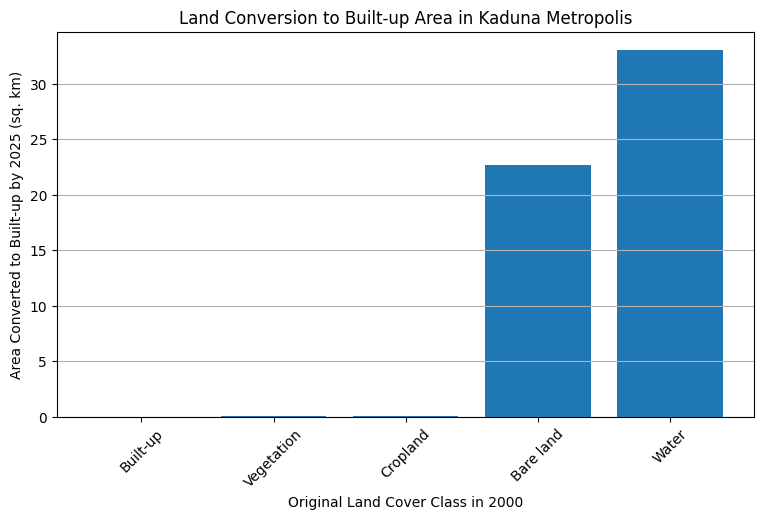

In [54]:
plt.figure(figsize=(9, 5))
plt.bar(conversion_df["original_class_name"], conversion_df["converted_to_builtup_sqkm"])
plt.xlabel("Original Land Cover Class in 2000")
plt.ylabel("Area Converted to Built-up by 2025 (sq. km)")
plt.title("Land Conversion to Built-up Area in Kaduna Metropolis")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

## 30. Export hotspot grid table to Google Drive

In [55]:
task = ee.batch.Export.table.toDrive(
    collection=hotspot_grid,
    description="kaduna_urban_growth_hotspot_grid",
    folder="GeoAI_Kaduna_Urban_Growth",
    fileNamePrefix="kaduna_urban_growth_hotspot_grid",
    fileFormat="CSV"
)
task.start()
print("Export started for hotspot grid CSV. Check Google Drive folder: GeoAI_Kaduna_Urban_Growth")

Export started for hotspot grid CSV. Check Google Drive folder: GeoAI_Kaduna_Urban_Growth


## 31. Export classified LULC maps to Google Drive

In [56]:
for year in years:
    task = ee.batch.Export.image.toDrive(
        image=classified_images[year].toByte(),
        description=f"kaduna_lulc_{year}",
        folder="GeoAI_Kaduna_Urban_Growth",
        fileNamePrefix=f"kaduna_lulc_{year}",
        region=aoi,
        scale=30,
        maxPixels=1e13
    )
    task.start()
    print(f"Export started for LULC {year}")

Export started for LULC 2000
Export started for LULC 2005
Export started for LULC 2010
Export started for LULC 2015
Export started for LULC 2020
Export started for LULC 2025


## 32. Export new built-up growth map to Google Drive

In [57]:
task = ee.batch.Export.image.toDrive(
    image=new_growth_2000_2025.toByte(),
    description="kaduna_new_builtup_growth_2000_2025",
    folder="GeoAI_Kaduna_Urban_Growth",
    fileNamePrefix="kaduna_new_builtup_growth_2000_2025",
    region=aoi,
    scale=30,
    maxPixels=1e13
)
task.start()
print("Export started for new built-up growth map.")

Export started for new built-up growth map.


## 33. Export hotspot image to Google Drive

In [58]:
task = ee.batch.Export.image.toDrive(
    image=hotspot_image.toByte(),
    description="kaduna_urban_growth_hotspot_map",
    folder="GeoAI_Kaduna_Urban_Growth",
    fileNamePrefix="kaduna_urban_growth_hotspot_map",
    region=aoi,
    scale=100,
    maxPixels=1e13
)
task.start()
print("Export started for hotspot map.")

Export started for hotspot map.


## 34. Export land conversion map to Google Drive

In [59]:
task = ee.batch.Export.image.toDrive(
    image=converted_from.toByte(),
    description="kaduna_land_converted_to_builtup_2000_2025",
    folder="GeoAI_Kaduna_Urban_Growth",
    fileNamePrefix="kaduna_land_converted_to_builtup_2000_2025",
    region=aoi,
    scale=30,
    maxPixels=1e13
)
task.start()
print("Export started for land conversion map.")

Export started for land conversion map.


## 35. Save summary tables locally in Colab

In [60]:
area_df.to_csv("kaduna_builtup_area_statistics.csv", index=False)
conversion_df.to_csv("kaduna_land_conversion_statistics.csv", index=False)
print("CSV files saved in Colab runtime.")

CSV files saved in Colab runtime.


## 36. Download summary tables from Colab

In [61]:
from google.colab import files

files.download("kaduna_builtup_area_statistics.csv")
files.download("kaduna_land_conversion_statistics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Methodology statement for your paper

Multi-temporal Landsat satellite imagery was processed using Google Earth Engine to assess urban growth in Kaduna Metropolis. Annual dry-season composites were generated for selected years between 2000 and 2025. Spectral bands and indices including NDVI, NDBI, MNDWI, and BSI were used as predictor variables. A Random Forest classifier was trained using reference land-cover samples derived from ESA WorldCover and applied to classify the study area into built-up land, vegetation, cropland, bare land, and water. Built-up areas were extracted from each classified image to quantify urban expansion over time. Change detection was used to identify newly built-up areas, while grid-based spatial aggregation was applied to detect urban growth hotspots. Land conversion analysis was conducted to identify which land-cover classes were converted into built-up areas. The outputs include land-cover maps, built-up growth statistics, hotspot maps, and land conversion summaries for sustainable urban planning.

## Recommended improvements for academic-quality results

1. Replace or complement ESA WorldCover labels with manually digitized training samples.
2. Add Sentinel-2 classification for 2020 and 2025 for higher-resolution recent mapping.
3. Use a formal Getis-Ord Gi* or Local Moran's I hotspot test after exporting the grid CSV.
4. Add road-distance and population-density variables to analyze growth drivers.
5. Validate built-up results using Google Open Buildings or Microsoft Building Footprints.
6. Compare Random Forest with XGBoost, SVM, or LightGBM.
7. Add SHAP explainability if running models outside Earth Engine in Python.
8. Prepare final map layouts in QGIS for publication-quality figures.

## 37. Publication-grade figure generation add-on

The cells below convert the analysis outputs into publication and presentation-ready figures. They assume the earlier workflow has already created `aoi`, `kaduna_metro`, `years`, `composites`, `classified_images`, `builtup_images`, `area_df`, `conversion_df`, `new_growth_2000_2025`, `hotspot_grid`, `hotspot_image`, and `converted_from`.


### 37.1 Install figure-generation dependencies and create output folder


In [ ]:
!pip install pillow requests -q

import os
import requests
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

OUTPUT_DIR = Path('/content/kaduna_geoai_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Figures will be saved here:', OUTPUT_DIR)


### 37.2 Helper functions for Earth Engine thumbnails and figure panels


In [ ]:
def download_ee_thumbnail(image, vis_params, region, filename, dimensions=1800):
    """Download a styled Earth Engine image as a PNG thumbnail."""
    styled = image.visualize(**vis_params)
    url = styled.getThumbURL({
        'region': region,
        'dimensions': dimensions,
        'format': 'png'
    })

    response = requests.get(url)
    if response.status_code != 200:
        raise Exception(f'Failed to download {filename}. Status code: {response.status_code}')

    output_path = OUTPUT_DIR / filename
    with open(output_path, 'wb') as f:
        f.write(response.content)

    print('Saved:', output_path)
    return output_path


def get_region_from_aoi(aoi):
    """Convert the AOI geometry to thumbnail-compatible coordinates."""
    return aoi.bounds().getInfo()['coordinates']


def create_image_panel(image_paths, titles, output_filename, main_title=None, cols=2, figsize=(12, 10)):
    """Create a multi-panel figure from downloaded PNG images."""
    rows = (len(image_paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    if len(image_paths) == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for ax, img_path, title in zip(axes, image_paths, titles):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(title, fontsize=13, weight='bold')
        ax.axis('off')

    for ax in axes[len(image_paths):]:
        ax.axis('off')

    if main_title:
        fig.suptitle(main_title, fontsize=16, weight='bold', y=0.98)

    plt.tight_layout()
    output_path = OUTPUT_DIR / output_filename
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()

    print('Saved panel:', output_path)
    return output_path


region = get_region_from_aoi(aoi)
available_years = sorted([int(y) for y in composites.keys()])
preferred_panel_years = [2000, 2010, 2020, 2025]
panel_years = [y for y in preferred_panel_years if y in available_years]

if len(panel_years) < 4:
    candidate_years = [available_years[0]]
    candidate_years += [y for y in [2010, 2020] if y in available_years]
    candidate_years += [available_years[-1]]
    panel_years = []
    for y in candidate_years:
        if y not in panel_years:
            panel_years.append(y)

baseline_year = panel_years[0]
final_year = panel_years[-1]
mid_year_1 = 2010 if 2010 in builtup_images else panel_years[min(1, len(panel_years) - 1)]
mid_year_2 = 2020 if 2020 in builtup_images else panel_years[max(len(panel_years) - 2, 0)]

print('AOI region prepared.')
print('Panel years:', panel_years)
print('Growth benchmark years:', baseline_year, mid_year_1, mid_year_2, final_year)


### 37.3 Figure 1 - Study area map


In [ ]:
study_area_outline = ee.Image().byte().paint(
    featureCollection=kaduna_metro,
    color=1,
    width=3
)

study_area_vis = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '000000']
}

fig1_path = download_ee_thumbnail(
    image=study_area_outline,
    vis_params=study_area_vis,
    region=region,
    filename='figure_1_study_area_kaduna_metro.png',
    dimensions=1800
)


### 37.4 Figure 2 - Multi-year satellite image panel


In [ ]:
rgb_vis = {
    'bands': ['red', 'green', 'blue'],
    'min': 0.02,
    'max': 0.30
}

satellite_paths = []
for year in panel_years:
    path = download_ee_thumbnail(
        image=composites[year],
        vis_params=rgb_vis,
        region=region,
        filename=f'satellite_rgb_{year}.png',
        dimensions=1800
    )
    satellite_paths.append(path)

fig2_path = create_image_panel(
    image_paths=satellite_paths,
    titles=[f'Satellite Image: {y}' for y in panel_years],
    output_filename='figure_2_multiyear_satellite_panel.png',
    main_title='Multi-Year Satellite Imagery of Kaduna Metropolis',
    cols=2,
    figsize=(12, 10)
)


### 37.5 Figure 3 - Multi-year LULC classification panel and legend


In [ ]:
lulc_palette = [
    'd7191c',  # Built-up
    '1a9641',  # Vegetation
    'ffff00',  # Cropland
    'a6611a',  # Bare land
    '2c7bb6'   # Water
]

lulc_vis = {
    'min': 1,
    'max': 5,
    'palette': lulc_palette
}

lulc_paths = []
for year in panel_years:
    path = download_ee_thumbnail(
        image=classified_images[year],
        vis_params=lulc_vis,
        region=region,
        filename=f'lulc_classification_{year}.png',
        dimensions=1800
    )
    lulc_paths.append(path)

fig3_path = create_image_panel(
    image_paths=lulc_paths,
    titles=[f'LULC Classification: {y}' for y in panel_years],
    output_filename='figure_3_multiyear_lulc_panel.png',
    main_title='Land Use and Land Cover Classification of Kaduna Metropolis',
    cols=2,
    figsize=(12, 10)
)

labels = ['Built-up', 'Vegetation', 'Cropland', 'Bare land', 'Water']
colors = ['#d7191c', '#1a9641', '#ffff00', '#a6611a', '#2c7bb6']
patches = [mpatches.Patch(color=color, label=label) for color, label in zip(colors, labels)]

fig, ax = plt.subplots(figsize=(7, 1.2))
ax.legend(handles=patches, loc='center', ncol=5, frameon=False, fontsize=11)
ax.axis('off')
lulc_legend_path = OUTPUT_DIR / 'lulc_legend.png'
plt.savefig(lulc_legend_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved legend:', lulc_legend_path)


### 37.6 Figure 4 - Built-up expansion change map


In [ ]:
builtup_baseline = builtup_images[baseline_year]
builtup_mid1 = builtup_images[mid_year_1]
builtup_mid2 = builtup_images[mid_year_2]
builtup_final = builtup_images[final_year]

growth_baseline_to_mid1 = builtup_mid1.And(builtup_baseline.Not())
growth_mid1_to_mid2 = builtup_mid2.And(builtup_mid1.Not())
growth_mid2_to_final = builtup_final.And(builtup_mid2.Not())

builtup_expansion_map = (
    ee.Image(0)
    .where(builtup_baseline.eq(1), 1)
    .where(growth_baseline_to_mid1.eq(1), 2)
    .where(growth_mid1_to_mid2.eq(1), 3)
    .where(growth_mid2_to_final.eq(1), 4)
    .rename('builtup_growth_period')
    .clip(aoi)
)

builtup_expansion_vis = {
    'min': 0,
    'max': 4,
    'palette': ['f2f2f2', '4d4d4d', 'fdbb84', 'ef6548', 'b30000']
}

fig4_path = download_ee_thumbnail(
    image=builtup_expansion_map,
    vis_params=builtup_expansion_vis,
    region=region,
    filename='figure_4_builtup_expansion_change_map.png',
    dimensions=2000
)

labels = [
    'Stable non-built-up',
    f'Built-up by {baseline_year}',
    f'New built-up {baseline_year}-{mid_year_1}',
    f'New built-up {mid_year_1}-{mid_year_2}',
    f'New built-up {mid_year_2}-{final_year}',
]
colors = ['#f2f2f2', '#4d4d4d', '#fdbb84', '#ef6548', '#b30000']
patches = [mpatches.Patch(color=color, label=label) for color, label in zip(colors, labels)]

fig, ax = plt.subplots(figsize=(11, 1.5))
ax.legend(handles=patches, loc='center', ncol=2, frameon=False, fontsize=10)
ax.axis('off')
builtup_expansion_legend_path = OUTPUT_DIR / 'builtup_expansion_legend.png'
plt.savefig(builtup_expansion_legend_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved legend:', builtup_expansion_legend_path)


### 37.7 Figure 5 - Urban growth hotspot map and legend


In [ ]:
hotspot_vis = {
    'min': 1,
    'max': 5,
    'palette': ['f7f7f7', 'fee5d9', 'fcae91', 'fb6a4a', 'cb181d']
}

fig5_path = download_ee_thumbnail(
    image=hotspot_image,
    vis_params=hotspot_vis,
    region=region,
    filename='figure_5_urban_growth_hotspot_map.png',
    dimensions=2000
)

labels = ['Stable / no growth', 'Low growth', 'Moderate growth', 'High growth', 'Very high growth hotspot']
colors = ['#f7f7f7', '#fee5d9', '#fcae91', '#fb6a4a', '#cb181d']
patches = [mpatches.Patch(color=color, label=label) for color, label in zip(colors, labels)]

fig, ax = plt.subplots(figsize=(10, 1.4))
ax.legend(handles=patches, loc='center', ncol=2, frameon=False, fontsize=10)
ax.axis('off')
hotspot_legend_path = OUTPUT_DIR / 'hotspot_legend.png'
plt.savefig(hotspot_legend_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved legend:', hotspot_legend_path)


### 37.8 Figure 6 - Land conversion map


In [ ]:
conversion_map_vis = {
    'min': 1,
    'max': 5,
    'palette': ['d7191c', '1a9641', 'ffff00', 'a6611a', '2c7bb6']
}

fig6_path = download_ee_thumbnail(
    image=converted_from,
    vis_params=conversion_map_vis,
    region=region,
    filename='figure_6_land_conversion_to_builtup_map.png',
    dimensions=2000
)


### 37.9 Figure 7 - Built-up area trend chart


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(area_df['year'], area_df['builtup_area_sqkm'], marker='o', linewidth=2)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Built-up area (sq. km)', fontsize=12)
ax.set_title('Built-up Area Growth in Kaduna Metropolis', fontsize=14, weight='bold')
ax.grid(True, linestyle='--', alpha=0.5)

for x, y in zip(area_df['year'], area_df['builtup_area_sqkm']):
    ax.text(x, y, f'{y:.1f}', fontsize=9, ha='center', va='bottom')

plt.tight_layout()
fig7_path = OUTPUT_DIR / 'figure_7_builtup_area_trend_chart.png'
plt.savefig(fig7_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', fig7_path)


### 37.10 Figure 8 - Land conversion bar chart


In [ ]:
conversion_plot_df = conversion_df.copy()
conversion_plot_df = conversion_plot_df[conversion_plot_df['original_class_name'] != 'Built-up']

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(conversion_plot_df['original_class_name'], conversion_plot_df['converted_to_builtup_sqkm'])
ax.set_xlabel('Original land-cover class', fontsize=12)
ax.set_ylabel('Area converted to built-up (sq. km)', fontsize=12)
ax.set_title('Land Converted to Built-up Area', fontsize=14, weight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)

for i, value in enumerate(conversion_plot_df['converted_to_builtup_sqkm']):
    ax.text(i, value, f'{value:.1f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
fig8_path = OUTPUT_DIR / 'figure_8_land_conversion_bar_chart.png'
plt.savefig(fig8_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', fig8_path)


### 37.11 Figure 9 - Before-after hotspot comparison panels


In [ ]:
top_hotspots = hotspot_grid.sort('growth_sqkm', False).limit(4)
top_hotspot_list = top_hotspots.toList(4)


def get_feature_region(feature, buffer_meters=900):
    geom = ee.Feature(feature).geometry().centroid().buffer(buffer_meters).bounds()
    return geom.getInfo()['coordinates']


before_after_paths = []
for i in range(4):
    feature = ee.Feature(top_hotspot_list.get(i))
    hotspot_region = get_feature_region(feature, buffer_meters=900)

    before_path = download_ee_thumbnail(
        image=composites[baseline_year],
        vis_params=rgb_vis,
        region=hotspot_region,
        filename=f'hotspot_{i + 1}_satellite_{baseline_year}.png',
        dimensions=1000
    )
    after_path = download_ee_thumbnail(
        image=composites[final_year],
        vis_params=rgb_vis,
        region=hotspot_region,
        filename=f'hotspot_{i + 1}_satellite_{final_year}.png',
        dimensions=1000
    )
    before_after_paths.append((before_path, after_path))

fig, axes = plt.subplots(4, 2, figsize=(10, 16))
for i, (before_path, after_path) in enumerate(before_after_paths):
    before_img = Image.open(before_path)
    after_img = Image.open(after_path)

    axes[i, 0].imshow(before_img)
    axes[i, 0].set_title(f'Hotspot {i + 1}: {baseline_year}', fontsize=12, weight='bold')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(after_img)
    axes[i, 1].set_title(f'Hotspot {i + 1}: {final_year}', fontsize=12, weight='bold')
    axes[i, 1].axis('off')

fig.suptitle('Before-After Satellite Evidence of Urban Growth Hotspots', fontsize=16, weight='bold', y=0.995)
plt.tight_layout()
fig9_path = OUTPUT_DIR / 'figure_9_before_after_hotspot_panels.png'
plt.savefig(fig9_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', fig9_path)


### 37.12 Figure 10 - Growth interval panel


In [ ]:
interval_growth_images = {
    f'{baseline_year}-{mid_year_1}': growth_baseline_to_mid1,
    f'{mid_year_1}-{mid_year_2}': growth_mid1_to_mid2,
    f'{mid_year_2}-{final_year}': growth_mid2_to_final
}

interval_growth_vis = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', 'd7191c']
}

interval_paths = []
for label, img in interval_growth_images.items():
    safe_label = label.replace('-', '_')
    path = download_ee_thumbnail(
        image=img,
        vis_params=interval_growth_vis,
        region=region,
        filename=f'growth_interval_{safe_label}.png',
        dimensions=1800
    )
    interval_paths.append(path)

fig10_path = create_image_panel(
    image_paths=interval_paths,
    titles=[f'New Built-up Growth: {label}' for label in interval_growth_images.keys()],
    output_filename='figure_10_growth_interval_panel.png',
    main_title='Urban Growth by Time Interval',
    cols=3,
    figsize=(15, 5)
)


### 37.13 Figure 11 - Satellite versus classification comparison


In [ ]:
comparison_year = final_year

sat_path = download_ee_thumbnail(
    image=composites[comparison_year],
    vis_params=rgb_vis,
    region=region,
    filename=f'comparison_satellite_{comparison_year}.png',
    dimensions=1800
)

class_path = download_ee_thumbnail(
    image=classified_images[comparison_year],
    vis_params=lulc_vis,
    region=region,
    filename=f'comparison_lulc_{comparison_year}.png',
    dimensions=1800
)

fig11_path = create_image_panel(
    image_paths=[sat_path, class_path],
    titles=[f'Satellite Image: {comparison_year}', f'Classified LULC: {comparison_year}'],
    output_filename='figure_11_satellite_vs_classification.png',
    main_title=f'Satellite Image and Classified Land Cover for {comparison_year}',
    cols=2,
    figsize=(12, 6)
)


### 37.14 Figure 12 - Built-up statistics table


In [ ]:
summary_table = area_df.copy()
for column in ['builtup_area_sqkm', 'change_sqkm', 'percentage_change']:
    if column in summary_table.columns:
        summary_table[column] = summary_table[column].round(2)
summary_table = summary_table.fillna('-')

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')
table = ax.table(
    cellText=summary_table.values,
    colLabels=summary_table.columns,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
ax.set_title('Built-up Area Statistics for Kaduna Metropolis', fontsize=14, weight='bold', pad=12)

fig12_path = OUTPUT_DIR / 'figure_12_builtup_statistics_table.png'
plt.savefig(fig12_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', fig12_path)


### 37.15 Export figure data and package all outputs


In [ ]:
area_df.to_csv(OUTPUT_DIR / 'builtup_area_statistics_for_figures.csv', index=False)
conversion_df.to_csv(OUTPUT_DIR / 'land_conversion_statistics_for_figures.csv', index=False)
print('Figure data exported as CSV.')

zip_path = shutil.make_archive(
    base_name='/content/kaduna_geoai_figures',
    format='zip',
    root_dir=OUTPUT_DIR
)
print('Zipped figures:', zip_path)

from google.colab import files
files.download('/content/kaduna_geoai_figures.zip')
